# Baybayin recognition — 8-layer CNN with image augmentation

This image-only version preserves the uploaded notebook's nested ZIP ingestion,
image normalization, export-based split, callbacks, reports, and model export.
The model has **eight Conv2D layers**, followed by global pooling and a classifier.
There is no BiLSTM, stroke input, or sequence preprocessing. Batch normalization,
activation, pooling, dropout, and dense classifier layers are additional Keras layers.

**Data needed:** the original `BAYA_DATASETS.zip`, containing nested export ZIPs
with `attempts.json` and PNG images. Only `attemptId`, `targetClass`, and `imageUri`
are read from the JSON; stroke records are not required. Keep each export intact
for splitting. The JSON supplies image labels and paths.

**Run:** open in Google Colab (GPU recommended) and run top to bottom. The upload
step prompts for the ZIP. In local Jupyter, set `DATASET_ZIP_PATH` in Step 2 or the
`BAYA_DATASET_ZIP` environment variable, then run all cells. `BAYA_WORK_DIR` optionally
changes the workspace. Requires Python 3.10+ and TensorFlow 2.16+; validation uses
TensorFlow 2.20. If needed, run `%pip install tensorflow numpy pandas pillow
matplotlib scikit-learn` in a separate cell, then restart the kernel.

Augmentation is generated afresh during training; validation and test images remain
unchanged. Inspect the augmentation preview before a long run. Actual accuracy must
be measured with your dataset; the notebook contains no retained training results.

API references: [Keras model saving](https://keras.io/api/models/model_saving_apis/model_saving_and_loading/)
and [TensorFlow PyDataset](https://www.tensorflow.org/api_docs/python/tf/keras/utils/PyDataset).

# **Step 1 — Import libraries and set reproducibility**
A fixed seed makes the group split and model initialization more reproducible.

In [ ]:
import os
import json
import math
import random
import shutil
import zipfile
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow.keras import layers, Model

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Configure the experiment

- Input: 96 × 96 grayscale handwriting images
- CNN filters: 32, 32, 64, 64, 128, 128, 256, 256 (eight convolution layers)
- Pooling after each pair of convolution layers: 96 → 48 → 24 → 12 → 6
- Batch size: 32; initial learning rate: 0.001; maximum epochs: 60
- Training-only augmentation: small rotations, uniform scaling, and translations

Edit `DATASET_ZIP_PATH` for local use. Checkpoints use version 1.1 and a new CNN-only
name. Re-running this experiment overwrites its own checkpoint; change the version
or workspace to retain separate runs.


In [ ]:
# ---------- Experiment configuration ----------
IMG_HEIGHT = 96
IMG_WIDTH = 96
IMG_CHANNELS = 1
CNN_FILTERS = (32, 32, 64, 64, 128, 128, 256, 256)
BATCH_SIZE = 32
EPOCHS = 60
LEARNING_RATE = 1e-3

AUGMENTATION_ENABLED = True
AUG_ROTATION_DEGREES = 8.0
AUG_SCALE_RANGE = (0.90, 1.10)
AUG_TRANSLATION_FRACTION = 0.03
AUG_PROBABILITY = 0.80

MODEL_NAME = "Baybayin_CustomCNN8"
MODEL_VERSION = "1.1"

# In local Jupyter, set a path here, e.g. Path("BAYA_DATASETS.zip").
DATASET_ZIP_PATH = (
    Path(os.environ["BAYA_DATASET_ZIP"]).expanduser()
    if os.environ.get("BAYA_DATASET_ZIP") else None
)
WORK_DIR = Path(os.environ.get(
    "BAYA_WORK_DIR", "/content" if Path("/content").is_dir()
    else str(Path.cwd() / "baya_workspace")
)).expanduser().resolve()
UPLOAD_DIR = WORK_DIR / "baya_upload"
OUTER_EXTRACT_DIR = WORK_DIR / "baya_outer_extracted"
EXTRACT_DIR = WORK_DIR / "baya_exports_extracted"
OUTPUT_DIR = WORK_DIR / "baya_cnn8_output_v1_1"

EXPECTED_EXPORTS = 14
EXPECTED_CLASSES = 63
EXPECTED_ATTEMPTS_PER_EXPORT = 315
EXPECTED_TOTAL_SAMPLES = EXPECTED_EXPORTS * EXPECTED_ATTEMPTS_PER_EXPORT

for folder in [UPLOAD_DIR, OUTER_EXTRACT_DIR, EXTRACT_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / f"{MODEL_NAME}_cp_{MODEL_VERSION}.keras"
FINAL_MODEL_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{MODEL_VERSION}.keras"
print("Workspace:", WORK_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("Final model:", FINAL_MODEL_PATH)
print("Expected exports / samples:", EXPECTED_EXPORTS, EXPECTED_TOTAL_SAMPLES)


Workspace: /content
Checkpoint: /content/baya_cnn8_output_v1_1/Baybayin_CustomCNN8_cp_1.1.keras
Final model: /content/baya_cnn8_output_v1_1/Baybayin_CustomCNN8_1.1.keras
Expected exports / samples: 14 4410


## Step 3 — Upload the Dataset


In [ ]:
# Use a configured ZIP in local Jupyter, or the original Colab upload workflow.
try:
    from google.colab import files
except ImportError:
    files = None

if DATASET_ZIP_PATH is not None:
    OUTER_ZIP_PATH = Path(DATASET_ZIP_PATH).expanduser().resolve()
    if not OUTER_ZIP_PATH.is_file():
        raise FileNotFoundError(f"Dataset ZIP not found: {OUTER_ZIP_PATH}")
elif files is not None:
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(zip_names) != 1:
        raise ValueError("Upload exactly one outer ZIP: BAYA_DATASETS.zip.")
    uploaded_name = zip_names[0]
    OUTER_ZIP_PATH = UPLOAD_DIR / Path(uploaded_name).name
    OUTER_ZIP_PATH.write_bytes(uploaded[uploaded_name])
    del uploaded
else:
    raise FileNotFoundError(
        "Set DATASET_ZIP_PATH in Step 2 to your BAYA_DATASETS.zip, then rerun."
    )
if not zipfile.is_zipfile(OUTER_ZIP_PATH):
    raise ValueError(f"Not a valid ZIP file: {OUTER_ZIP_PATH}")
print("Outer dataset ZIP:", OUTER_ZIP_PATH)
print(f"Size: {OUTER_ZIP_PATH.stat().st_size / (1024**2):.2f} MB")


Saving BAYA_DATASETS.zip to BAYA_DATASETS.zip
Outer dataset ZIP: /content/baya_upload/BAYA_DATASETS.zip
Size: 35.46 MB


## Step 4 — Extract the outer ZIP, find the 14 nested ZIPs, and extract each export

This performs both extraction levels automatically.

In [ ]:
def safe_extract_zip(zip_path: Path, destination: Path):
    # Extract ZIP contents while blocking paths that escape the destination.
    destination.mkdir(parents=True, exist_ok=True)
    destination_resolved = destination.resolve()

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if destination_resolved not in target.parents and target != destination_resolved:
                raise ValueError(f"Unsafe path inside ZIP: {member.filename}")
        zf.extractall(destination)


for folder in [OUTER_EXTRACT_DIR, EXTRACT_DIR]:
    if folder.resolve().parent != WORK_DIR.resolve():
        raise ValueError("Extraction directories must be direct workspace children.")
    if folder.resolve() in OUTER_ZIP_PATH.resolve().parents:
        raise ValueError("Move the input ZIP outside the temporary extraction folders.")

# Clean only temporary extraction folders so rerunning this cell
# cannot mix an old extraction with a newly uploaded dataset.
for folder in [OUTER_EXTRACT_DIR, EXTRACT_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)

# ---------- Level 1: extract BAYA_DATASETS.zip ----------
safe_extract_zip(OUTER_ZIP_PATH, OUTER_EXTRACT_DIR)

# Find all nested dataset ZIP files.
inner_zip_files = sorted(OUTER_EXTRACT_DIR.rglob("*.zip"))

if not inner_zip_files:
    raise FileNotFoundError(
        "No inner BAYA dataset ZIP files were found inside the uploaded outer ZIP."
    )

print(f"Found {len(inner_zip_files)} inner dataset ZIP file(s):")
for z in inner_zip_files:
    print(" -", z.relative_to(OUTER_EXTRACT_DIR))

if len(inner_zip_files) != EXPECTED_EXPORTS:
    print(
        f"\nWARNING: Expected {EXPECTED_EXPORTS} inner exports, "
        f"but found {len(inner_zip_files)}."
    )

# ---------- Level 2: extract each BAYA_dataset_*.zip ----------
seen_export_ids = set()
for inner_zip in inner_zip_files:
    export_id = inner_zip.stem
    if export_id in seen_export_ids:
        raise ValueError(f"Duplicate inner export name: {export_id}")
    seen_export_ids.add(export_id)
    target = EXTRACT_DIR / export_id
    safe_extract_zip(inner_zip, target)

print(f"\nSuccessfully extracted {len(inner_zip_files)} source export(s).")
print("Extracted exports are stored under:")
print(EXTRACT_DIR)


Found 14 inner dataset ZIP file(s):
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T03-51-35-334Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T05-43-06-183Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T06-40-53-944Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T07-47-28-468Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T08-33-47-340Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T04-12-06-104Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T08-10-00-545Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T09-02-49-162Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T10-34-50-057Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T09-50-54-498Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T09-54-32-545Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T10-03-56-331Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T11-55-03-985Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T15-13-05-394Z.zip

Successfully extracted 14 source export(s).
Extracted exports are stored under:
/content/baya_exports_extracted


## Step 5 — Read labels and image paths from each export

Build the master index from `source_export`, `attemptId`, `targetClass`, and the
corresponding PNG path. Stroke, timing, and canvas metadata are not used.


In [ ]:
records = []

export_folders = sorted(
    folder for folder in EXTRACT_DIR.iterdir()
    if folder.is_dir()
)

for export_folder in export_folders:
    attempts_files = list(export_folder.rglob("attempts.json"))

    if len(attempts_files) == 0:
        print("WARNING: No attempts.json found in:", export_folder.name)
        continue

    if len(attempts_files) > 1:
        print(
            f"WARNING: Multiple attempts.json files found in {export_folder.name}. "
            "All will be read."
        )

    for attempts_file in attempts_files:
        export_root = attempts_file.parent

        with open(attempts_file, "r", encoding="utf-8") as f:
            attempts = json.load(f)

        for rec in attempts:
            attempt_id = rec.get("attemptId")
            label = rec.get("targetClass")

            image_uri = rec.get("imageUri")
            if image_uri:
                image_path = export_root / image_uri
            else:
                image_path = export_root / "images" / f"attempt_{attempt_id}.png"

            records.append({
                "source_export": export_folder.name,
                "attempt_id": attempt_id,
                "label": label,
                "image_path": str(image_path),
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No handwriting attempts were loaded from the extracted exports.")

print("Total records:", len(df))
print("Unique classes:", df["label"].nunique())
print("Unique source exports:", df["source_export"].nunique())

print("\nRecords per source export:")
display(
    df.groupby("source_export")
      .size()
      .rename("samples")
      .to_frame()
)

display(
    df[["source_export", "attempt_id", "label", "image_path"]].head()
)


Total records: 4410
Unique classes: 63
Unique source exports: 14

Records per source export:


,samples
source_export,
BAYA_dataset_2026-09-12T03-51-35-334Z,315
BAYA_dataset_2026-09-12T05-43-06-183Z,315
BAYA_dataset_2026-09-12T06-40-53-944Z,315
BAYA_dataset_2026-09-12T07-47-28-468Z,315
BAYA_dataset_2026-09-12T08-33-47-340Z,315
BAYA_dataset_2026-09-13T04-12-06-104Z,315
BAYA_dataset_2026-09-13T08-10-00-545Z,315
BAYA_dataset_2026-09-13T09-02-49-162Z,315
BAYA_dataset_2026-09-13T10-34-50-057Z,315


,source_export,attempt_id,label,image_path
0,BAYA_dataset_2026-09-12T03-51-35-334Z,2c200622-c344-46fc-96ac-a6cfa38260b0,a,/content/baya_exports_extracted/BAYA_dataset_2...
1,BAYA_dataset_2026-09-12T03-51-35-334Z,78568eb0-ec63-4fb2-9e39-2266dfd0b261,a,/content/baya_exports_extracted/BAYA_dataset_2...
2,BAYA_dataset_2026-09-12T03-51-35-334Z,17d7330b-0e73-465f-8e8e-816c53dc368e,a,/content/baya_exports_extracted/BAYA_dataset_2...
3,BAYA_dataset_2026-09-12T03-51-35-334Z,c46b7565-c197-42b1-b5cb-1922d0bd1adb,a,/content/baya_exports_extracted/BAYA_dataset_2...
4,BAYA_dataset_2026-09-12T03-51-35-334Z,6bfd3fc2-6f3f-4869-8b2f-163a9c166a60,a,/content/baya_exports_extracted/BAYA_dataset_2...


## Step 6 — Validate the complete combined dataset before training


In [ ]:
missing_labels = df["label"].isna().sum()
blank_labels = df["label"].astype(str).str.strip().eq("").sum()
missing_ids = df["attempt_id"].isna().sum()
df["image_exists"] = df["image_path"].apply(lambda p: Path(p).is_file())
missing_images = (~df["image_exists"]).sum()
duplicate_attempts = df.duplicated(["source_export", "attempt_id"]).sum()

print("========== DATASET VALIDATION ==========")
print("Source exports:", df["source_export"].nunique())
print("Classes:", df["label"].nunique())
print("Total samples:", len(df))
if missing_labels or blank_labels:
    raise ValueError("Dataset contains missing or blank targetClass labels.")
if missing_ids:
    raise ValueError("Dataset contains missing attemptId values.")
if missing_images:
    raise FileNotFoundError(
        f"Missing {missing_images} image(s): "
        f"{df.loc[~df['image_exists'], 'image_path'].head(10).tolist()}"
    )
if duplicate_attempts:
    raise ValueError(f"Found {duplicate_attempts} duplicate export/attempt pairs.")
for description, actual, expected in [
    ("exports", df["source_export"].nunique(), EXPECTED_EXPORTS),
    ("classes", df["label"].nunique(), EXPECTED_CLASSES),
    ("samples", len(df), EXPECTED_TOTAL_SAMPLES),
]:
    if actual != expected:
        print(f"WARNING: Expected {expected} {description}, found {actual}.")

display(df.groupby("source_export").size().rename("samples").to_frame())
display(df["label"].value_counts().sort_index().to_frame("samples"))
print("Image-only metadata validation completed.")


========== DATASET VALIDATION ==========
Source exports: 14
Classes: 63
Total samples: 4410


,samples
source_export,
BAYA_dataset_2026-09-12T03-51-35-334Z,315
BAYA_dataset_2026-09-12T05-43-06-183Z,315
BAYA_dataset_2026-09-12T06-40-53-944Z,315
BAYA_dataset_2026-09-12T07-47-28-468Z,315
BAYA_dataset_2026-09-12T08-33-47-340Z,315
BAYA_dataset_2026-09-13T04-12-06-104Z,315
BAYA_dataset_2026-09-13T08-10-00-545Z,315
BAYA_dataset_2026-09-13T09-02-49-162Z,315
BAYA_dataset_2026-09-13T10-34-50-057Z,315


,samples
label,
a,70
b,70
ba,70
be_bi,70
bo_bu,70
...,...
wo_wu,70
y,70
ya,70


Image-only metadata validation completed.


## Step 7 — Visual sanity check

Inspect random examples if the displayed class label matches the handwritten character.

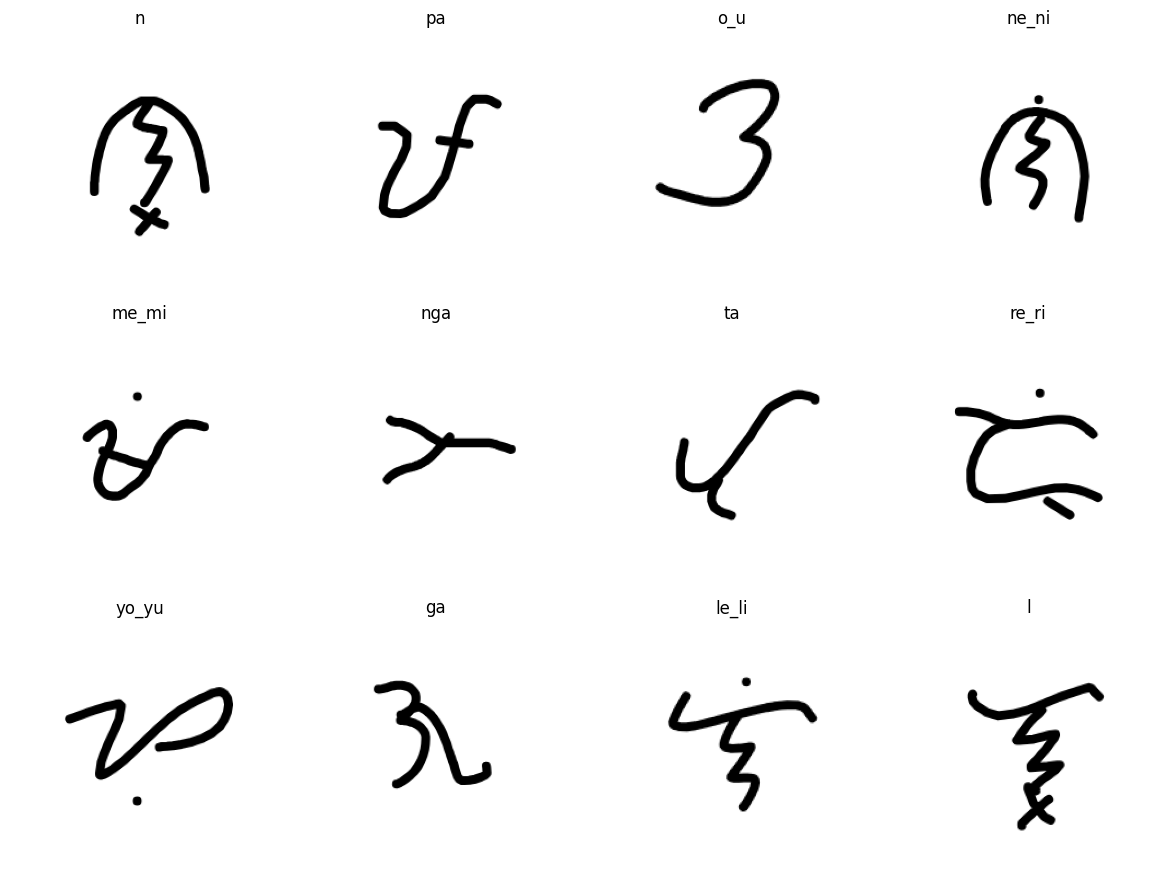

In [ ]:
sample_rows = df.sample(min(12, len(df)), random_state=SEED).reset_index(drop=True)

plt.figure(figsize=(12, 9))

for i, row in sample_rows.iterrows():
    img = Image.open(row["image_path"]).convert("RGBA")

    # Composite transparent images onto white.
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)
    gray = bg.convert("L")

    plt.subplot(3, 4, i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(str(row["label"]))
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 8 — Create the label mapping

In [ ]:
classes = sorted(df["label"].astype(str).unique())
label_to_id = {label: idx for idx, label in enumerate(classes)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

df["label_id"] = df["label"].astype(str).map(label_to_id).astype("int32")

NUM_CLASSES = len(classes)

print("Number of classes:", NUM_CLASSES)
print("First 20 mappings:")
for label in classes[:20]:
    print(f"{label:12s} -> {label_to_id[label]}")

if NUM_CLASSES != 63:
    print(f"\nNOTE: Current combined dataset has {NUM_CLASSES} classes instead of 63.")

Number of classes: 63
First 20 mappings:
a            -> 0
b            -> 1
ba           -> 2
be_bi        -> 3
bo_bu        -> 4
d            -> 5
da_ra        -> 6
de_di        -> 7
do_du        -> 8
e_i          -> 9
g            -> 10
ga           -> 11
ge_gi        -> 12
go_gu        -> 13
h            -> 14
ha           -> 15
he_hi        -> 16
ho_hu        -> 17
k            -> 18
ka           -> 19


## Step 9 — Define position and size-normalized image preprocessing

1. finds the handwriting bounding box;
2. crops around all visible handwriting, including kudlit marks;
3. adds proportional padding;
4. centers the crop on a square background;
5. preserves the character's aspect ratio;
6. resizes the standardized square to **96 × 96**.

Image tensor shape: (96, 96, 1)
Pixel range: 0.0 to 1.0


/tmp/ipykernel_897/2494837767.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


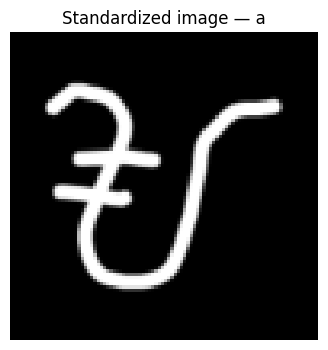

In [ ]:
IMAGE_PADDING_RATIO = 0.15
INK_THRESHOLD = 0.08


def load_image_array(image_path):
    # 1. Load and place transparent images on white.
    img = Image.open(image_path).convert("RGBA")
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)

    # 2. Convert to grayscale.
    gray = bg.convert("L")
    arr = np.asarray(gray, dtype=np.float32) / 255.0

    # 3. Convert black handwriting to high-valued ink.
    #    white background -> 0
    #    black handwriting -> 1
    ink = 1.0 - arr

    # 4. Detect all visible handwriting.
    mask = ink > INK_THRESHOLD

    if np.any(mask):
        ys, xs = np.where(mask)

        y0, y1 = int(ys.min()), int(ys.max()) + 1
        x0, x1 = int(xs.min()), int(xs.max()) + 1

        # 5. Crop to the handwriting bounding box.
        crop = ink[y0:y1, x0:x1]

        crop_h, crop_w = crop.shape
        max_dim = max(crop_h, crop_w)

        # 6. Add proportional padding around the character.
        padding = max(2, int(round(max_dim * IMAGE_PADDING_RATIO)))
        square_side = max_dim + 2 * padding

        # 7. Center on a square canvas while preserving aspect ratio.
        square = np.zeros((square_side, square_side), dtype=np.float32)

        top = (square_side - crop_h) // 2
        left = (square_side - crop_w) // 2

        square[top:top + crop_h, left:left + crop_w] = crop
    else:
        # Fallback for an unexpectedly blank image.
        square = ink

    # 8. Resize only after centering / scale normalization.
    square_u8 = np.clip(square * 255.0, 0, 255).astype(np.uint8)
    standardized = Image.fromarray(square_u8, mode="L").resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR,
    )

    result = np.asarray(standardized, dtype=np.float32) / 255.0

    # H x W x 1
    result = np.expand_dims(result, axis=-1)
    return result.astype(np.float32)


# Quick preprocessing check
test_img = load_image_array(df.iloc[0]["image_path"])

print("Image tensor shape:", test_img.shape)
print("Pixel range:", float(test_img.min()), "to", float(test_img.max()))

plt.figure(figsize=(4, 4))
plt.imshow(test_img[..., 0], cmap="gray")
plt.title(f"Standardized image — {df.iloc[0]['label']}")
plt.axis("off")
plt.show()

## Step 10 — Split by complete source export: 10 / 2 / 2

Because your current `BAYA_DATASETS.zip` contains **14 complete exports**, this notebook uses:

```
10 exports → Training
 2 exports → Validation
 2 exports → Testing
```

If every export contains 315 attempts, this gives:

```
Training:   3,150 samples
Validation:   630 samples
Testing:      630 samples
```

The split is performed by **whole export**, never by random individual PNG.

This helps prevent repeated attempts from the same collection session from being divided between training and testing.

> Important: `source_export` is a collection-session identifier, not necessarily a person identifier. If the same participant produced multiple ZIP exports, those exports should later be grouped under the same participant before the final thesis evaluation.

In [ ]:
groups = sorted(df["source_export"].unique())

if len(groups) < 3:
    raise ValueError(
        f"Need at least 3 source exports for group splitting; found {len(groups)}."
    )

rng = np.random.default_rng(SEED)
shuffled_groups = np.array(groups, dtype=object)
rng.shuffle(shuffled_groups)

# For the current 14-export dataset: exactly 10 train / 2 val / 2 test.
if len(groups) == 14:
    n_test = 2
    n_val = 2
else:
    # General fallback if the dataset changes later.
    n_test = max(1, round(len(groups) * 0.15))
    n_val = max(1, round(len(groups) * 0.15))

    while n_test + n_val >= len(groups):
        if n_val > 1:
            n_val -= 1
        elif n_test > 1:
            n_test -= 1
        else:
            break

test_groups = list(shuffled_groups[:n_test])
val_groups = list(shuffled_groups[n_test:n_test + n_val])
train_groups = list(shuffled_groups[n_test + n_val:])

train_df = df[df["source_export"].isin(train_groups)].reset_index(drop=True)
val_df = df[df["source_export"].isin(val_groups)].reset_index(drop=True)
test_df = df[df["source_export"].isin(test_groups)].reset_index(drop=True)

print("========== GROUP SPLIT ==========")
print(f"TRAIN ({len(train_groups)} exports)")
for g in train_groups:
    print(" -", g)

print(f"\nVALIDATION ({len(val_groups)} exports)")
for g in val_groups:
    print(" -", g)

print(f"\nTEST ({len(test_groups)} exports)")
for g in test_groups:
    print(" -", g)

print("\nSample counts")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

# Verify there is no source-export leakage.
assert set(train_groups).isdisjoint(val_groups)
assert set(train_groups).isdisjoint(test_groups)
assert set(val_groups).isdisjoint(test_groups)

# Check that every split contains all labels.
for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing = sorted(set(classes) - set(part["label"].astype(str)))
    print(
        f"{name}: exports={part['source_export'].nunique()}, "
        f"samples={len(part)}, "
        f"classes={part['label'].nunique()}, "
        f"missing={len(missing)}"
    )
    if missing:
        print(" Missing labels:", missing[:20])
if set(classes) - set(train_df["label"].astype(str)):
    raise ValueError("Training exports do not contain all classes. Review the group split.")


========== GROUP SPLIT ==========
TRAIN (10 exports)
 - BAYA_dataset_2026-09-12T03-51-35-334Z
 - BAYA_dataset_2026-09-16T10-03-56-331Z
 - BAYA_dataset_2026-09-16T15-13-05-394Z
 - BAYA_dataset_2026-09-16T09-54-32-545Z
 - BAYA_dataset_2026-09-13T04-12-06-104Z
 - BAYA_dataset_2026-09-12T06-40-53-944Z
 - BAYA_dataset_2026-09-12T08-33-47-340Z
 - BAYA_dataset_2026-09-16T11-55-03-985Z
 - BAYA_dataset_2026-09-12T05-43-06-183Z
 - BAYA_dataset_2026-09-13T10-34-50-057Z

VALIDATION (2 exports)
 - BAYA_dataset_2026-09-16T09-50-54-498Z
 - BAYA_dataset_2026-09-12T07-47-28-468Z

TEST (2 exports)
 - BAYA_dataset_2026-09-13T08-10-00-545Z
 - BAYA_dataset_2026-09-13T09-02-49-162Z

Sample counts
Train: 3150
Validation: 630
Test: 630
Total: 4410
train: exports=10, samples=3150, classes=63, missing=0
validation: exports=2, samples=630, classes=63, missing=0
test: exports=2, samples=630, classes=63, missing=0


## Step 11 — Convert each split into image tensors

- `Ximg_*`: float32 arrays with shape `(N, 96, 96, 1)`
- `y_*`: integer class IDs

White background maps to zero; dark ink maps to values near one. All original
arrays remain unaugmented. Augmentation is applied to training batches only.


In [ ]:
def dataframe_to_arrays(part_df, name="dataset"):
    if part_df.empty:
        raise ValueError(f"The {name} split is empty.")
    images, labels = [], []
    for i, row in part_df.iterrows():
        image = load_image_array(row["image_path"])
        if not np.isfinite(image).all():
            raise ValueError(f"Non-finite image values: {row['image_path']}")
        if not np.any(image > INK_THRESHOLD):
            raise ValueError(f"Image contains no detectable ink: {row['image_path']}")
        images.append(image)
        labels.append(int(row["label_id"]))
        if (i + 1) % 250 == 0:
            print(f"{name}: processed {i + 1}/{len(part_df)}")
    return np.stack(images).astype(np.float32), np.asarray(labels, dtype=np.int32)

Ximg_train, y_train = dataframe_to_arrays(train_df, "train")
Ximg_val, y_val = dataframe_to_arrays(val_df, "validation")
Ximg_test, y_test = dataframe_to_arrays(test_df, "test")
for name, images, labels in [
    ("Train", Ximg_train, y_train),
    ("Validation", Ximg_val, y_val),
    ("Test", Ximg_test, y_test),
]:
    print(name, "images:", images.shape, "labels:", labels.shape)


/tmp/ipykernel_897/2494837767.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


train: processed 250/3150
train: processed 500/3150
train: processed 750/3150
train: processed 1000/3150
train: processed 1250/3150
train: processed 1500/3150
train: processed 1750/3150
train: processed 2000/3150
train: processed 2250/3150
train: processed 2500/3150
train: processed 2750/3150
train: processed 3000/3150
validation: processed 250/630
validation: processed 500/630
test: processed 250/630
test: processed 500/630
Train images: (3150, 96, 96, 1) labels: (3150,)
Validation images: (630, 96, 96, 1) labels: (630,)
Test images: (630, 96, 96, 1) labels: (630,)


## Training-only image augmentation

### Training-only handwriting augmentation

Small random rotations (up to ±8°), scale changes (0.90–1.10×), and translations (up to 3% of the canvas) are applied on the fly to 80% of training images. These conservative changes approximate writing variation while retaining orientation and kudlit marks. There are no flips, crops, erasing, or mark removal. A bounds check includes all nonzero ink, including faint pixels and an interpolation margin; if no sampled transform fits, the image is retained unchanged. Bilinear resampling can slightly soften small marks, so compare validation results with `AUGMENTATION_ENABLED = False` when tuning.

The generator preserves source images and labels, shuffles training samples deterministically, and creates reproducible transforms from the seed, epoch, and original sample index. Validation and test images remain unchanged. The image-only CNN accepts its returned image batches directly. Set `shuffle=False` in `model.fit`, because the generator already manages sample order. Keep configuration constants unchanged during a training run.

In [ ]:
# Training-only, label-preserving augmentation of standardized handwriting.
# Keep geometric changes small: kudlit marks and orientation distinguish classes.
# Augmentation settings are defined once in the experiment configuration cell.


def augment_handwriting_image(image, rng):
    """Transform a copy; keep all ink on the canvas and fall back if needed."""
    result = np.asarray(image, dtype=np.float32).copy()
    if result.ndim != 3 or result.shape[-1] != 1:
        raise ValueError("Expected a grayscale image with shape (height, width, 1).")
    if not np.isfinite(result).all():
        raise ValueError("Augmentation received non-finite image values.")
    if not AUGMENTATION_ENABLED or rng.random() >= AUG_PROBABILITY:
        return result

    height, width = result.shape[:2]
    ys, xs = np.nonzero(result[..., 0] > 0.0)
    if not len(xs):
        return result

    # Include faint ink and an extra interpolation margin around its bounding box.
    # Coordinates use the whole normalized canvas, with center (0.5, 0.5).
    lower = np.array([(xs.min() - 1) / width, (ys.min() - 1) / height])
    upper = np.array([(xs.max() + 2) / width, (ys.max() + 2) / height])
    corners = np.array([
        [lower[0], lower[1]], [upper[0], lower[1]],
        [lower[0], upper[1]], [upper[0], upper[1]],
    ], dtype=np.float64)
    center = np.array([0.5, 0.5])
    pixels = np.diag([float(width), float(height)])

    for _ in range(12):
        angle = np.deg2rad(rng.uniform(-AUG_ROTATION_DEGREES, AUG_ROTATION_DEGREES))
        scale = rng.uniform(*AUG_SCALE_RANGE)
        rotation = np.array([[np.cos(angle), -np.sin(angle)],
                             [np.sin(angle), np.cos(angle)]])
        linear = scale * rotation
        moved = (corners - center) @ linear.T + center
        # Sample only translations that keep the complete ink bounds in-frame.
        low = np.maximum(-AUG_TRANSLATION_FRACTION, -moved.min(axis=0))
        high = np.minimum(AUG_TRANSLATION_FRACTION, 1.0 - moved.max(axis=0))
        if np.any(low > high):
            continue
        translation = rng.uniform(low, high)
        offset = center - linear @ center + translation
        forward = pixels @ linear @ np.linalg.inv(pixels)
        forward_offset = pixels @ offset
        inverse = np.linalg.inv(forward)
        inverse_offset = -inverse @ forward_offset
        coefficients = (
            inverse[0, 0], inverse[0, 1], inverse_offset[0],
            inverse[1, 0], inverse[1, 1], inverse_offset[1],
        )
        warped = Image.fromarray(result[..., 0]).transform(
            (width, height), Image.Transform.AFFINE, coefficients,
            resample=Image.Resampling.BILINEAR, fillcolor=0.0,
        )
        transformed = np.asarray(warped, dtype=np.float32)
        return np.clip(transformed, 0.0, 1.0)[..., np.newaxis]

    # Unusual edge-filling inputs can leave no safe transform within these ranges.
    return result


class ImageAugmentationSequence(tf.keras.utils.Sequence):
    """Deterministic per-sample/epoch augmentation without changing source arrays."""

    def __init__(self, images, labels, batch_size=BATCH_SIZE, seed=SEED,
                 shuffle=True, **kwargs):
        # Supports Keras 3 worker/queue options when explicitly supplied.
        super().__init__(**kwargs)
        self.images = np.asarray(images)
        self.labels = np.asarray(labels)
        if len(self.images) != len(self.labels) or len(self.images) == 0:
            raise ValueError("Images and labels must have equal, nonzero lengths.")
        if self.images.ndim != 4 or self.images.shape[-1] != 1:
            raise ValueError("Expected images with shape (samples, height, width, 1).")
        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.shuffle = bool(shuffle)
        if self.batch_size < 1 or self.seed < 0:
            raise ValueError("batch_size must be positive and seed nonnegative.")
        if not (0.0 <= AUG_PROBABILITY <= 1.0):
            raise ValueError("AUG_PROBABILITY must be between 0 and 1.")
        if (len(AUG_SCALE_RANGE) != 2 or not 0 < AUG_SCALE_RANGE[0] <= AUG_SCALE_RANGE[1]
                or AUG_ROTATION_DEGREES < 0 or AUG_TRANSLATION_FRACTION < 0):
            raise ValueError("Invalid augmentation ranges.")
        self._state = self._make_state(0)

    def _make_state(self, epoch):
        indices = np.arange(len(self.labels))
        if self.shuffle:
            rng = np.random.default_rng(np.random.SeedSequence([self.seed, epoch, 0]))
            rng.shuffle(indices)
        indices.setflags(write=False)
        return epoch, indices

    def __len__(self):
        return (len(self.labels) + self.batch_size - 1) // self.batch_size

    def __getitem__(self, batch_index):
        if batch_index < 0 or batch_index >= len(self):
            raise IndexError("Batch index out of range.")
        # A single immutable state snapshot keeps concurrent batch reads coherent.
        epoch, indices = self._state
        selected = indices[batch_index * self.batch_size:(batch_index + 1) * self.batch_size]
        batch_images = np.empty((len(selected),) + self.images.shape[1:], dtype=np.float32)
        for position, sample_index in enumerate(selected):
            rng = np.random.default_rng(np.random.SeedSequence([
                self.seed, epoch, 1, int(sample_index)
            ]))
            batch_images[position] = augment_handwriting_image(self.images[sample_index], rng)
        return batch_images, self.labels[selected].copy()

    def on_epoch_end(self):
        self._state = self._make_state(self._state[0] + 1)

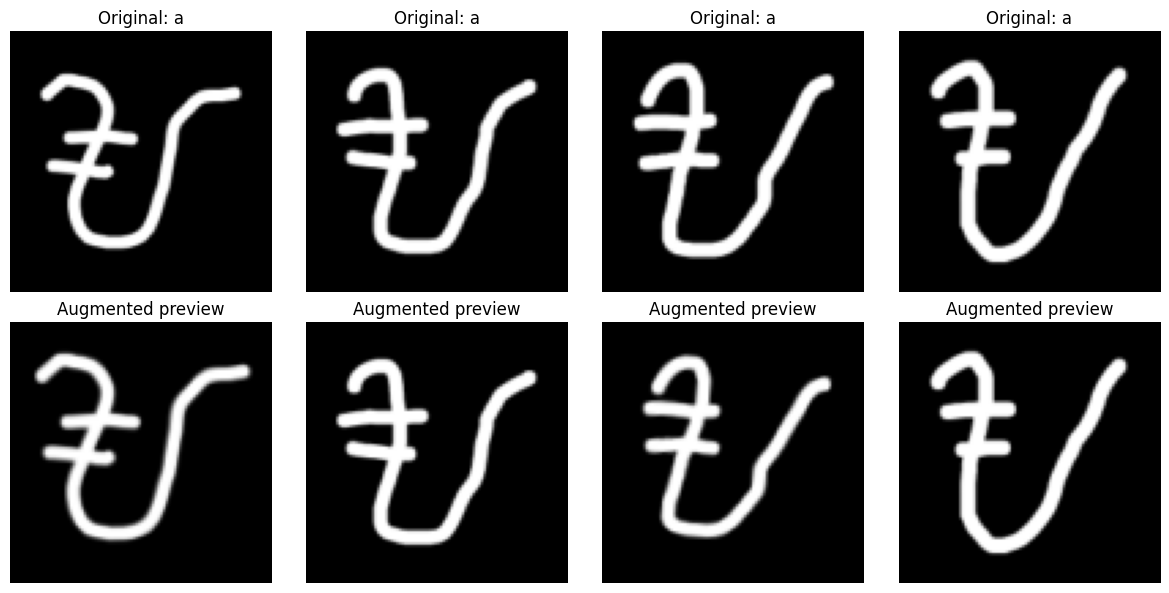

In [ ]:
# Visual preview uses a separate RNG and never modifies the training arrays.
preview_rng = np.random.default_rng(SEED)
preview_count = min(4, len(Ximg_train))
fig, axes = plt.subplots(2, preview_count, figsize=(3 * preview_count, 6), squeeze=False)
for i in range(preview_count):
    augmented = augment_handwriting_image(Ximg_train[i], preview_rng)
    axes[0, i].imshow(Ximg_train[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Original: {id_to_label[int(y_train[i])]}")
    axes[1, i].imshow(augmented[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Augmented preview")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

## Step 12 — Build the eight-layer CNN

| Block | Convolution layers | Filters | After max pooling |
|---|---|---|---|
| 1 | 1–2 | 32, 32 | 48 × 48 |
| 2 | 3–4 | 64, 64 | 24 × 24 |
| 3 | 5–6 | 128, 128 | 12 × 12 |
| 4 | 7–8 | 256, 256 | 6 × 6 |

Every convolution uses a 3 × 3 kernel, same padding, batch normalization, and ReLU.
Pooling occurs after each pair to avoid shrinking the 96 × 96 input too early.
Global average pooling → Dense 128 → Dropout 0.40 → class softmax completes the
classifier. The model receives one image tensor; no sequence input is needed.


In [ ]:
def build_custom_cnn(num_classes):
    if len(CNN_FILTERS) != 8:
        raise ValueError("CNN_FILTERS must define exactly eight convolution layers.")
    image_input = layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), name="image_input"
    )
    x = image_input
    for layer_number, filters in enumerate(CNN_FILTERS, start=1):
        x = layers.Conv2D(
            filters, 3, padding="same", use_bias=False,
            name=f"conv_{layer_number}"
        )(x)
        x = layers.BatchNormalization(name=f"bn_{layer_number}")(x)
        x = layers.ReLU(name=f"relu_{layer_number}")(x)
        if layer_number % 2 == 0:
            x = layers.MaxPooling2D(
                pool_size=2, name=f"pool_{layer_number // 2}"
            )(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = layers.Dense(128, activation="relu", name="image_features")(x)
    x = layers.Dropout(0.40, name="classifier_dropout")(x)
    output = layers.Dense(
        num_classes, activation="softmax", name="character_output"
    )(x)
    cnn = Model(image_input, output, name="BAYA_CustomCNN8")
    cnn.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE, clipnorm=1.0
        ),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"]
    )
    assert sum(isinstance(layer, layers.Conv2D) for layer in cnn.layers) == 8
    return cnn

model = build_custom_cnn(NUM_CLASSES)
model.summary()


Model: "BAYA_CustomCNN8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 96, 96, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 96, 96, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 96, 96, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 96, 96, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 48, 48, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (ReLU)                   │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_4 (BatchNormalization)       │ (None, 48, 48, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_4 (ReLU)                   │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_5 (Conv2D)                 │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_5 (BatchNormalization)       │ (None, 24, 24, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_5 (ReLU)                   │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_6 (Conv2D)                 │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_6 (BatchNormalization)       │ (None, 24, 24, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_6 (ReLU)                   │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_7 (Conv2D)                 │ (None, 12, 12, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_7 (BatchNormalization)       │ (None, 12, 12, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_7 (ReLU)                   │ (None, 12, 12, 256)    │             

 Total params: 1,215,583 (4.64 MB)

 Trainable params: 1,213,663 (4.63 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Step 13 — Define training callbacks

Three safeguards are used:

### 1. ModelCheckpoint
Stores the best model based on validation loss.

### 2. ReduceLROnPlateau
Reduces the learning rate when validation improvement stalls.

In [ ]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
]

## Step 14 — Train the CNN

Training batches receive fresh augmentation each epoch. Validation uses the original
normalized images. The data adapter shuffles sample order, so model-level shuffle
is disabled. Set `AUGMENTATION_ENABLED = False` in Step 2 for a baseline run.


In [ ]:
train_dataset = ImageAugmentationSequence(
    Ximg_train, y_train, batch_size=BATCH_SIZE, seed=SEED, shuffle=True
)
history = model.fit(
    train_dataset,
    validation_data=(Ximg_val, y_val),
    epochs=EPOCHS,
    callbacks=callbacks,
    shuffle=False,
    verbose=1,
)


Epoch 1/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.0699 - loss: 3.9493
Epoch 1: val_loss improved from None to 7.99643, saving model to /content/baya_cnn8_output_v1_1/Baybayin_CustomCNN8_cp_1.1.keras

Epoch 1: finished saving model to /content/baya_cnn8_output_v1_1/Baybayin_CustomCNN8_cp_1.1.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 46s 243ms/step - accuracy: 0.1260 - loss: 3.5518 - val_accuracy: 0.0159 - val_loss: 7.9964 - learning_rate: 0.0010
Epoch 2/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3054 - loss: 2.5097
Epoch 2: val_loss did not improve from 7.99643
99/99 ━━━━━━━━━━━━━━━━━━━━ 44s 38ms/step - accuracy: 0.3844 - loss: 2.2117 - val_accuracy: 0.0317 - val_loss: 13.3942 - learning_rate: 0.0010
Epoch 3/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6016 - loss: 1.4154
Epoch 3: val_loss did not improve from 7.99643
99/99 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.6533 - loss: 1.2432 - val_accuracy: 0.0159 - val_loss: 40.1470 - learning_rate: 0.00

## Step 15 — Plot learning curves

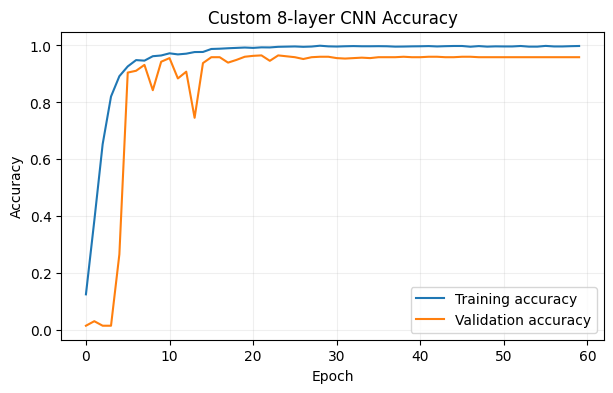

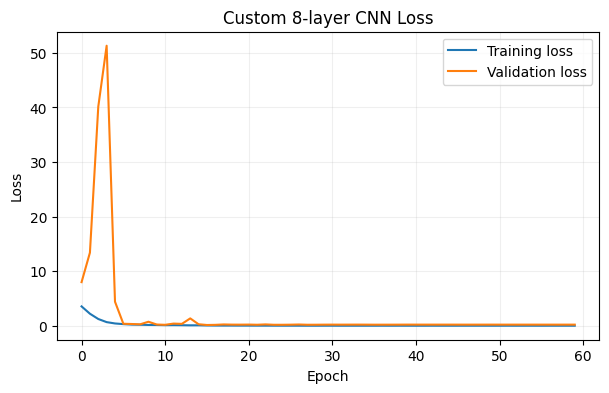

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom 8-layer CNN Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom 8-layer CNN Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Step 16 — Evaluate the best checkpoint on the untouched test export

In [ ]:
# Load the checkpoint selected by validation loss, then evaluate test images once.
best_model = tf.keras.models.load_model(CHECKPOINT_PATH)
test_probabilities = best_model.predict(Ximg_test, batch_size=BATCH_SIZE, verbose=1)
y_pred = np.argmax(test_probabilities, axis=1).astype(np.int32)
accuracy = accuracy_score(y_test, y_pred)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
)

# ============================================================
# MODEL 1 — ORGANIZED PER-CLASS TEST REPORT
# ============================================================

# Get per-class metrics
report = classification_report(
    y_test,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[id_to_label[i] for i in range(NUM_CLASSES)],
    output_dict=True,
    zero_division=0,
)

# Exact labels present in the dataset
all_labels = [id_to_label[i] for i in range(NUM_CLASSES)]


# ============================================================
# EXACT BAYA CLASS GROUPS
# 3 vowels + 15 base consonants +
# 15 A forms + 15 E/I forms + 15 O/U forms = 63 classes
# ============================================================

vowels = [
    "a",
    "e_i",
    "o_u",
]

base_consonants = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]

a_forms = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]

ei_forms = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]

ou_forms = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]


# ============================================================
# DISPLAY LABELS
# Makes the printed report easier to read.
# Does NOT change the actual dataset/model labels.
# ============================================================

display_names = {
    # Vowels
    "a": "a",
    "e_i": "e/i",
    "o_u": "o/u",

    # Base consonants
    "b": "b",
    "d": "d",
    "g": "g",
    "h": "h",
    "k": "k",
    "l": "l",
    "m": "m",
    "n": "n",
    "ng": "ng",
    "p": "p",
    "r": "r",
    "s": "s",
    "t": "t",
    "w": "w",
    "y": "y",

    # A forms
    "ba": "ba",
    "da_ra": "da/ra",
    "ga": "ga",
    "ha": "ha",
    "ka": "ka",
    "la": "la",
    "ma": "ma",
    "na": "na",
    "nga": "nga",
    "pa": "pa",
    "ra": "ra",
    "sa": "sa",
    "ta": "ta",
    "wa": "wa",
    "ya": "ya",

    # E/I forms
    "be_bi": "be/bi",
    "de_di": "de/di",
    "ge_gi": "ge/gi",
    "he_hi": "he/hi",
    "ke_ki": "ke/ki",
    "le_li": "le/li",
    "me_mi": "me/mi",
    "ne_ni": "ne/ni",
    "nge_ngi": "nge/ngi",
    "pe_pi": "pe/pi",
    "re_ri": "re/ri",
    "se_si": "se/si",
    "te_ti": "te/ti",
    "we_wi": "we/wi",
    "ye_yi": "ye/yi",

    # O/U forms
    "bo_bu": "bo/bu",
    "do_du": "do/du",
    "go_gu": "go/gu",
    "ho_hu": "ho/hu",
    "ko_ku": "ko/ku",
    "lo_lu": "lo/lu",
    "mo_mu": "mo/mu",
    "no_nu": "no/nu",
    "ngo_ngu": "ngo/ngu",
    "po_pu": "po/pu",
    "ro_ru": "ro/ru",
    "so_su": "so/su",
    "to_tu": "to/tu",
    "wo_wu": "wo/wu",
    "yo_yu": "yo/yu",
}


# ============================================================
# PRINT GROUP FUNCTION
# ============================================================

def print_group(title, labels):

    print("\n" + "=" * 82)
    print(title)
    print("=" * 82)

    print(
        f"{'Class':<20}"
        f"{'Precision':>12}"
        f"{'Recall':>12}"
        f"{'F1-score':>12}"
        f"{'Support':>10}"
    )

    print("-" * 82)

    precisions = []
    recalls = []
    f1_scores = []
    supports = []

    for label in labels:

        if label not in report:
            print(f"WARNING: {label} not found in classification report.")
            continue

        values = report[label]

        precision = values["precision"]
        recall = values["recall"]
        f1 = values["f1-score"]
        support = int(values["support"])

        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)
        supports.append(support)

        shown_label = display_names.get(label, label)

        print(
            f"{shown_label:<20}"
            f"{precision:>12.4f}"
            f"{recall:>12.4f}"
            f"{f1:>12.4f}"
            f"{support:>10}"
        )

    if precisions:

        print("-" * 82)

        print(
            f"{'GROUP AVG':<20}"
            f"{np.mean(precisions):>12.4f}"
            f"{np.mean(recalls):>12.4f}"
            f"{np.mean(f1_scores):>12.4f}"
            f"{sum(supports):>10}"
        )


# ============================================================
# OVERALL MODEL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("MODEL 1 — Custom 8-layer CNN TEST RESULTS")
print("=" * 65)

print(f"Accuracy:        {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision: {macro_precision:.4f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall:    {macro_recall:.4f} ({macro_recall * 100:.2f}%)")
print(f"Macro F1:        {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")


# ============================================================
# ORGANIZED CLASSIFICATION REPORT
# ============================================================

print_group(
    "1. VOWELS",
    vowels
)

print_group(
    "2. BASE CONSONANTS",
    base_consonants
)

print_group(
    "3. CONSONANTS — A FORM",
    a_forms
)

print_group(
    "4. CONSONANTS — E/I FORM",
    ei_forms
)

print_group(
    "5. CONSONANTS — O/U FORM",
    ou_forms
)


# ============================================================
# VERIFY ALL 63 CLASSES
# ============================================================

grouped_labels = (
    vowels
    + base_consonants
    + a_forms
    + ei_forms
    + ou_forms
)

missing_labels = sorted(
    set(all_labels) - set(grouped_labels)
)

extra_labels = sorted(
    set(grouped_labels) - set(all_labels)
)

duplicate_labels = sorted(
    {
        label
        for label in grouped_labels
        if grouped_labels.count(label) > 1
    }
)


print("\n" + "=" * 65)
print("GROUPING CHECK")
print("=" * 65)

print(f"Vowels:            {len(vowels)}")
print(f"Base consonants:   {len(base_consonants)}")
print(f"A forms:           {len(a_forms)}")
print(f"E/I forms:         {len(ei_forms)}")
print(f"O/U forms:         {len(ou_forms)}")
print("-" * 65)
print(f"Total grouped:     {len(grouped_labels)}")
print(f"Expected classes:  {NUM_CLASSES}")
print(f"Missing labels:    {len(missing_labels)}")
print(f"Extra labels:      {len(extra_labels)}")
print(f"Duplicates:        {len(duplicate_labels)}")


if missing_labels:
    print("\nMissing labels:")
    for label in missing_labels:
        print(" -", repr(label))

if extra_labels:
    print("\nExtra labels:")
    for label in extra_labels:
        print(" -", repr(label))

if duplicate_labels:
    print("\nDuplicate labels:")
    for label in duplicate_labels:
        print(" -", repr(label))


# ============================================================
# FINAL VALIDATION
# ============================================================

if (
    len(grouped_labels) == NUM_CLASSES
    and len(missing_labels) == 0
    and len(extra_labels) == 0
    and len(duplicate_labels) == 0
):
    print("\n✓ All 63 classes are correctly grouped exactly once.")
else:
    print("\n⚠ Check class grouping before using the report.")


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step

MODEL 1 — Custom 8-layer CNN TEST RESULTS
Accuracy:        0.9905 (99.05%)
Macro Precision: 0.9911 (99.11%)
Macro Recall:    0.9905 (99.05%)
Macro F1:        0.9905 (99.05%)

1. VOWELS
Class                  Precision      Recall    F1-score   Support
----------------------------------------------------------------------------------
a                         1.0000      1.0000      1.0000        10
e/i                       1.0000      1.0000      1.0000        10
o/u                       1.0000      1.0000      1.0000        10
----------------------------------------------------------------------------------
GROUP AVG                 1.0000      1.0000      1.0000        30

2. BASE CONSONANTS
Class                  Precision      Recall    F1-score   Support
----------------------------------------------------------------------------------
b                         1.0000      1.0000      1.0000        10
d                         1.0000    

## Step 17 — Confusion matrix

✓ All grouped labels found in dataset.


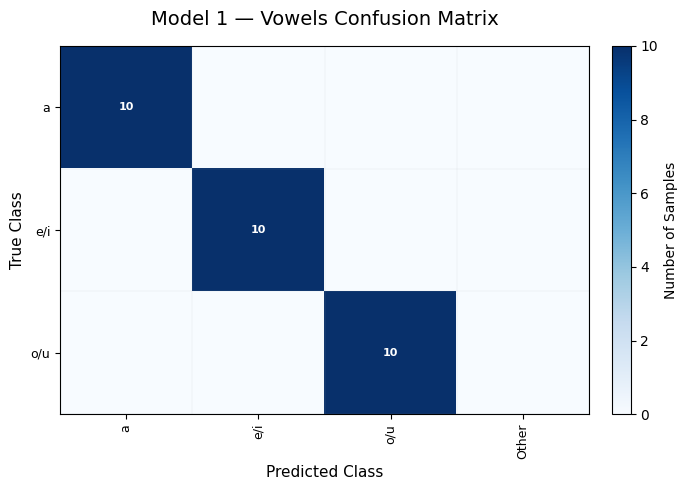


Model 1 — Vowels Confusion Matrix
Samples: 30
Correct predictions: 30
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


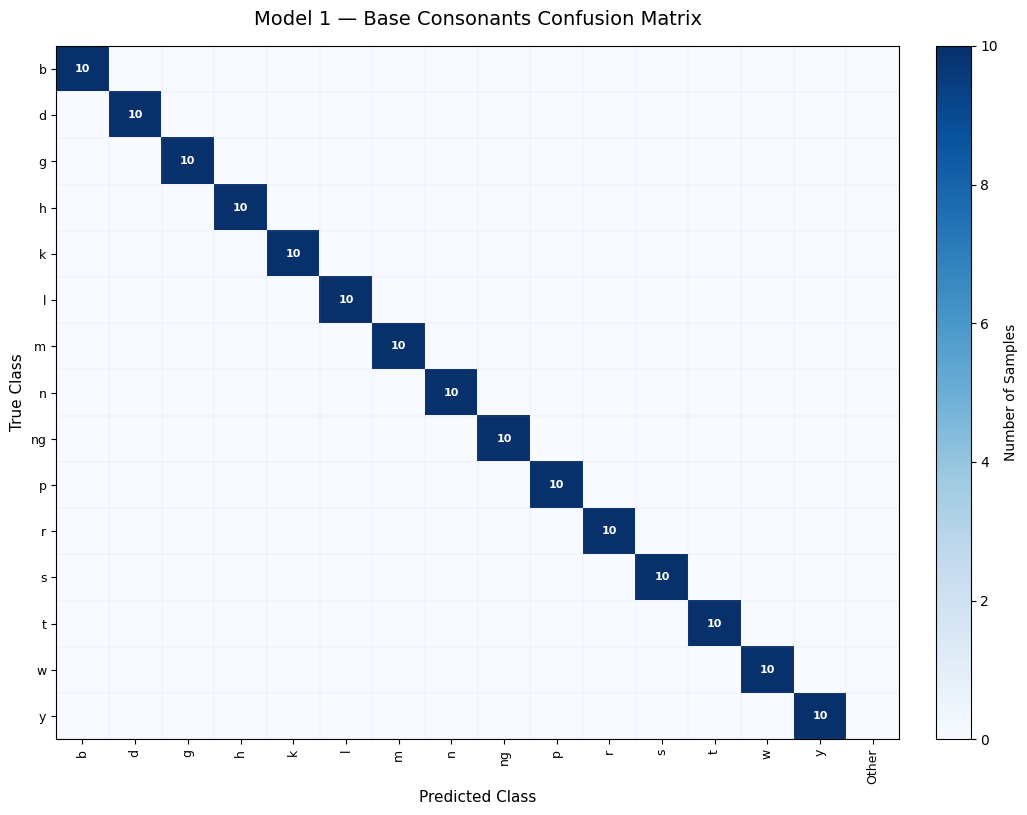


Model 1 — Base Consonants Confusion Matrix
Samples: 150
Correct predictions: 150
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


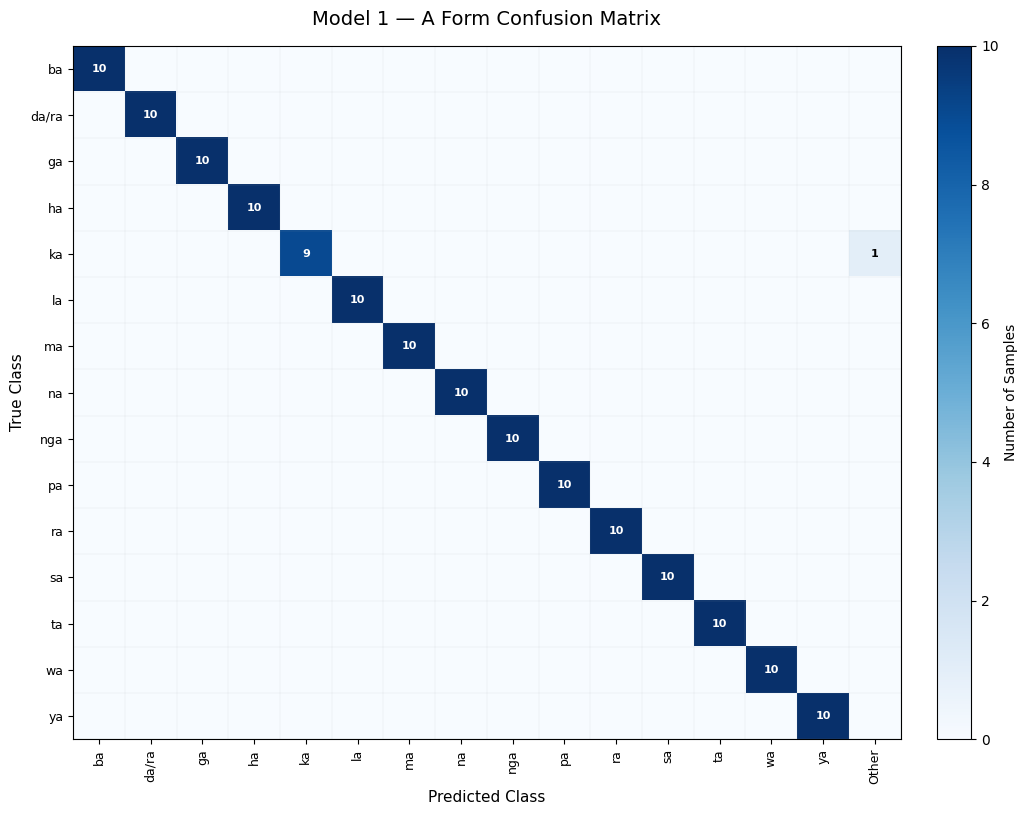


Model 1 — A Form Confusion Matrix
Samples: 150
Correct predictions: 149
Cross-group errors: 1
Group accuracy: 0.9933 (99.33%)
------------------------------------------------------------


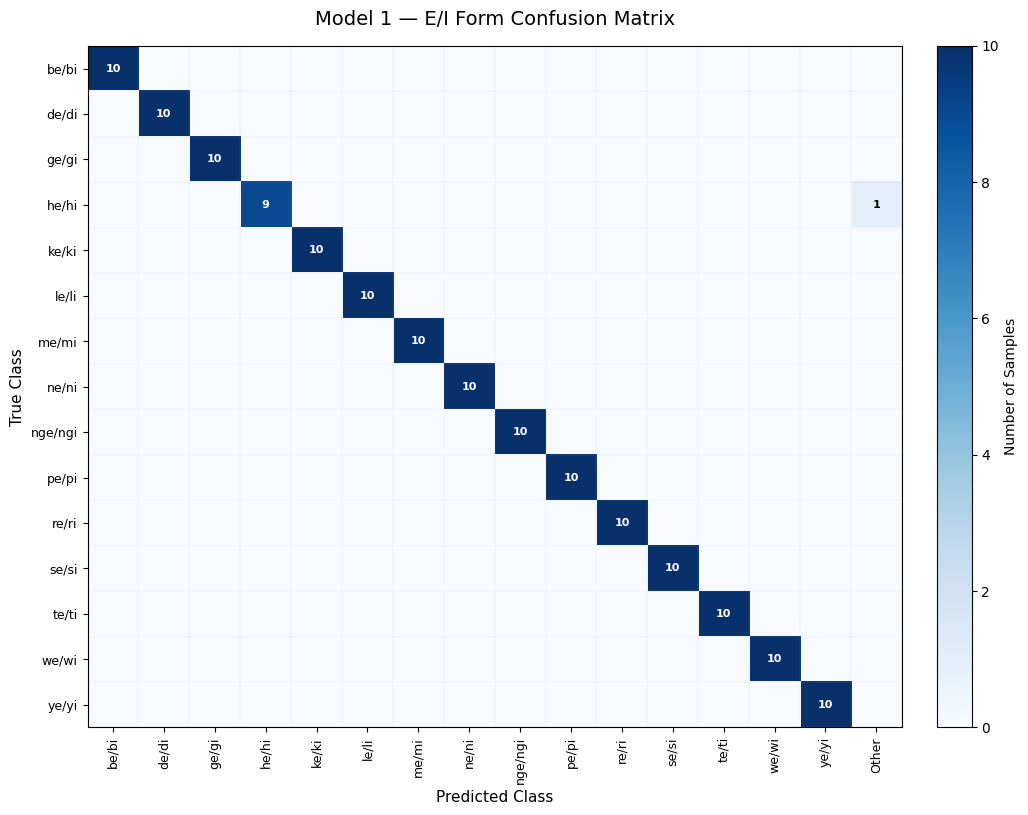


Model 1 — E/I Form Confusion Matrix
Samples: 150
Correct predictions: 149
Cross-group errors: 1
Group accuracy: 0.9933 (99.33%)
------------------------------------------------------------


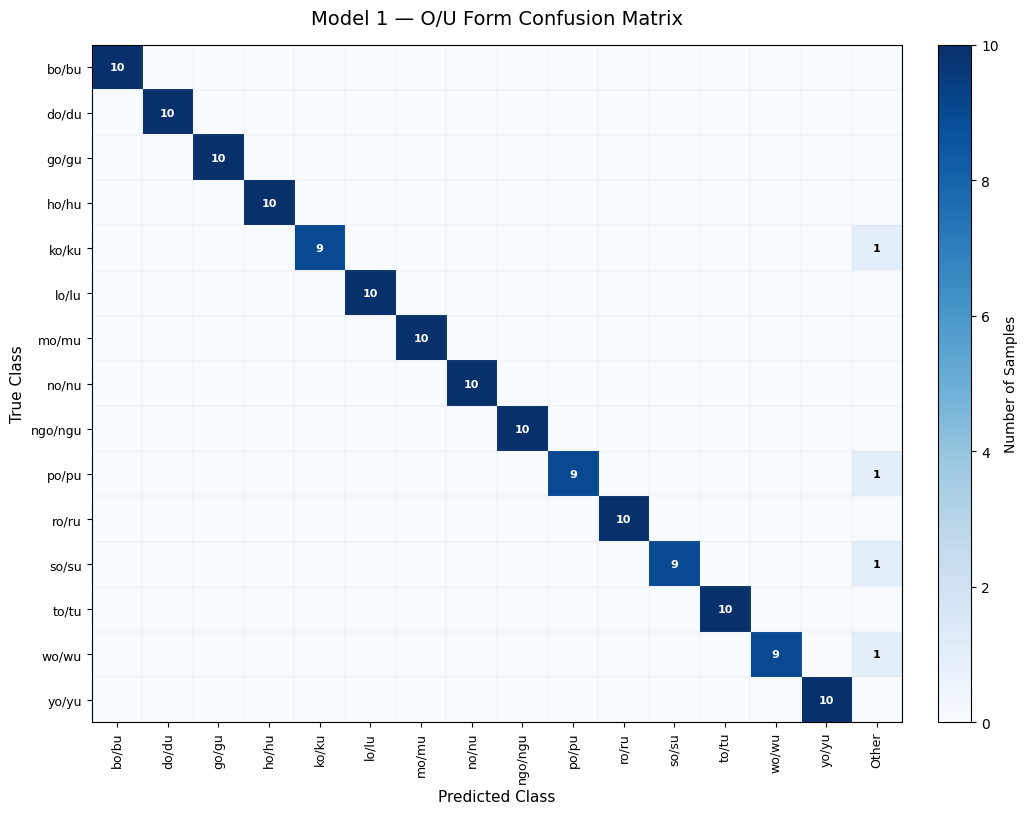


Model 1 — O/U Form Confusion Matrix
Samples: 150
Correct predictions: 146
Cross-group errors: 4
Group accuracy: 0.9733 (97.33%)
------------------------------------------------------------

MODEL 1 — SEPARATE CONFUSION MATRICES COMPLETE
Generated matrices:
1. Vowels
2. Base Consonants
3. A Forms
4. E/I Forms
5. O/U Forms


In [ ]:
# ============================================================
# STEP 18 — SEPARATE CONFUSION MATRICES
# MODEL 1: Custom 8-layer CNN
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# EXACT 63 BAYA CLASS GROUPS
# ============================================================

vowels = [
    "a",
    "e_i",
    "o_u",
]

base_consonants = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]

a_forms = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]

ei_forms = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]

ou_forms = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]


# ============================================================
# DISPLAY-FRIENDLY CLASS NAMES
# ============================================================

display_names = {
    # Vowels
    "a": "a",
    "e_i": "e/i",
    "o_u": "o/u",

    # Base consonants
    "b": "b",
    "d": "d",
    "g": "g",
    "h": "h",
    "k": "k",
    "l": "l",
    "m": "m",
    "n": "n",
    "ng": "ng",
    "p": "p",
    "r": "r",
    "s": "s",
    "t": "t",
    "w": "w",
    "y": "y",

    # A forms
    "ba": "ba",
    "da_ra": "da/ra",
    "ga": "ga",
    "ha": "ha",
    "ka": "ka",
    "la": "la",
    "ma": "ma",
    "na": "na",
    "nga": "nga",
    "pa": "pa",
    "ra": "ra",
    "sa": "sa",
    "ta": "ta",
    "wa": "wa",
    "ya": "ya",

    # E/I forms
    "be_bi": "be/bi",
    "de_di": "de/di",
    "ge_gi": "ge/gi",
    "he_hi": "he/hi",
    "ke_ki": "ke/ki",
    "le_li": "le/li",
    "me_mi": "me/mi",
    "ne_ni": "ne/ni",
    "nge_ngi": "nge/ngi",
    "pe_pi": "pe/pi",
    "re_ri": "re/ri",
    "se_si": "se/si",
    "te_ti": "te/ti",
    "we_wi": "we/wi",
    "ye_yi": "ye/yi",

    # O/U forms
    "bo_bu": "bo/bu",
    "do_du": "do/du",
    "go_gu": "go/gu",
    "ho_hu": "ho/hu",
    "ko_ku": "ko/ku",
    "lo_lu": "lo/lu",
    "mo_mu": "mo/mu",
    "no_nu": "no/nu",
    "ngo_ngu": "ngo/ngu",
    "po_pu": "po/pu",
    "ro_ru": "ro/ru",
    "so_su": "so/su",
    "to_tu": "to/tu",
    "wo_wu": "wo/wu",
    "yo_yu": "yo/yu",
}


# ============================================================
# LABEL NAME → NUMERIC CLASS ID
# ============================================================

label_to_id = {
    id_to_label[i]: i
    for i in range(NUM_CLASSES)
}


# ============================================================
# VERIFY ALL GROUP LABELS EXIST
# ============================================================

all_group_labels = (
    vowels
    + base_consonants
    + a_forms
    + ei_forms
    + ou_forms
)

missing_from_dataset = [
    label
    for label in all_group_labels
    if label not in label_to_id
]

if missing_from_dataset:
    print("WARNING: These labels were not found in id_to_label:")
    for label in missing_from_dataset:
        print(" -", label)
else:
    print("✓ All grouped labels found in dataset.")


# ============================================================
# FUNCTION TO BUILD AND PLOT ONE GROUP MATRIX
# ============================================================

def plot_group_confusion_matrix(
    title,
    group_labels,
    normalized=False
):

    # --------------------------------------------------------
    # Numeric IDs for the selected group
    # --------------------------------------------------------

    group_labels = [label for label in group_labels if label in label_to_id]
    if not group_labels:
        print(f"Skipping {title}: no labels from this group in the dataset.")
        return np.zeros((0, 1), dtype=np.int32)

    group_ids = [
        label_to_id[label]
        for label in group_labels
    ]

    # --------------------------------------------------------
    # Select only samples whose TRUE label is in this group
    # --------------------------------------------------------

    mask = np.isin(
        y_test,
        group_ids
    )

    y_true_group = y_test[mask]
    y_pred_group = y_pred[mask]

    n_classes = len(group_labels)

    # --------------------------------------------------------
    # Matrix dimensions:
    #
    # rows    = true classes in this group
    # columns = predicted classes in this group + Other
    # --------------------------------------------------------

    cm_group = np.zeros(
        (
            n_classes,
            n_classes + 1
        ),
        dtype=np.int32
    )

    # --------------------------------------------------------
    # Numeric class ID → position inside this group
    # --------------------------------------------------------

    id_to_position = {
        class_id: position
        for position, class_id
        in enumerate(group_ids)
    }

    # --------------------------------------------------------
    # Fill matrix
    # --------------------------------------------------------

    for true_id, pred_id in zip(
        y_true_group,
        y_pred_group
    ):

        row = id_to_position[
            int(true_id)
        ]

        # Prediction belongs to same group
        if int(pred_id) in id_to_position:

            col = id_to_position[
                int(pred_id)
            ]

        # Prediction belongs to another group
        else:

            col = n_classes

        cm_group[row, col] += 1


    # ========================================================
    # NORMALIZATION OPTION
    # ========================================================

    if normalized:

        row_totals = cm_group.sum(
            axis=1,
            keepdims=True
        )

        matrix_to_plot = np.divide(
            cm_group,
            row_totals,
            out=np.zeros_like(
                cm_group,
                dtype=float
            ),
            where=row_totals != 0
        )

        colorbar_label = "Proportion"

    else:

        matrix_to_plot = cm_group

        colorbar_label = "Number of Samples"


    # ========================================================
    # DISPLAY LABELS
    # ========================================================

    true_display_labels = [
        display_names.get(
            label,
            label
        )
        for label in group_labels
    ]

    predicted_display_labels = (
        true_display_labels
        + ["Other"]
    )


    # ========================================================
    # FIGURE SIZE
    # ========================================================

    figure_width = max(
        7,
        (n_classes + 1) * 0.65
    )

    figure_height = max(
        5,
        n_classes * 0.55
    )


    # ========================================================
    # PLOT
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(
            figure_width,
            figure_height
        )
    )

    im = ax.imshow(
    matrix_to_plot,
    interpolation="nearest",
    aspect="auto",
    cmap="Blues"
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=15
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=11
    )

    ax.set_ylabel(
        "True Class",
        fontsize=11
    )


    # --------------------------------------------------------
    # X-axis labels
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(
            n_classes + 1
        )
    )

    ax.set_xticklabels(
        predicted_display_labels,
        rotation=90,
        fontsize=9
    )


    # --------------------------------------------------------
    # Y-axis labels
    # --------------------------------------------------------

    ax.set_yticks(
        np.arange(
            n_classes
        )
    )

    ax.set_yticklabels(
        true_display_labels,
        fontsize=9
    )


    # --------------------------------------------------------
    # Color bar
    # --------------------------------------------------------

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label=colorbar_label
    )

    # ========================================================
    # WRITE VALUES INSIDE EACH CELL
    # White text on dark blue cells
    # Black text on light blue cells
    # ========================================================

    max_value = matrix_to_plot.max()

    # Threshold can be adjusted if needed
    threshold = max_value * 0.50

    for row in range(n_classes):

        for col in range(n_classes + 1):

            value = matrix_to_plot[row, col]

            if normalized:

                cell_text = (
                    f"{value:.2f}"
                    if value > 0
                    else ""
                )

            else:

                cell_text = (
                    str(int(value))
                    if value > 0
                    else ""
                )

            if cell_text:

                text_color = (
                    "white"
                    if value >= threshold
                    else "black"
                )

                ax.text(
                    col,
                    row,
                    cell_text,
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color,
                    fontweight="bold"
                )


    # ========================================================
    # GRID LINES
    # ========================================================

    ax.set_xticks(
        np.arange(
            -0.5,
            n_classes + 1,
            1
        ),
        minor=True
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            n_classes,
            1
        ),
        minor=True
    )

    ax.grid(
        which="minor",
        linestyle="-",
        linewidth=0.3,
        alpha=0.3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


    plt.tight_layout()
    plt.show()


    # ========================================================
    # BASIC GROUP STATISTICS
    # ========================================================

    total_samples = cm_group.sum()

    correct_predictions = sum(
        cm_group[i, i]
        for i in range(
            n_classes
        )
    )

    cross_group_errors = cm_group[
        :,
        -1
    ].sum()

    group_accuracy = (
        correct_predictions
        / total_samples
        if total_samples > 0
        else 0
    )

    print(
        f"\n{title}"
    )

    print(
        f"Samples: {total_samples}"
    )

    print(
        f"Correct predictions: "
        f"{correct_predictions}"
    )

    print(
        f"Cross-group errors: "
        f"{cross_group_errors}"
    )

    print(
        f"Group accuracy: "
        f"{group_accuracy:.4f} "
        f"({group_accuracy * 100:.2f}%)"
    )

    print(
        "-" * 60
    )


    return cm_group


# ============================================================
# 1. VOWELS CONFUSION MATRIX
# ============================================================

cm_vowels = plot_group_confusion_matrix(
    title=(
        "Model 1 — Vowels Confusion Matrix"
    ),
    group_labels=vowels,
    normalized=False
)


# ============================================================
# 2. BASE CONSONANTS CONFUSION MATRIX
# ============================================================

cm_base_consonants = plot_group_confusion_matrix(
    title=(
        "Model 1 — Base Consonants Confusion Matrix"
    ),
    group_labels=base_consonants,
    normalized=False
)


# ============================================================
# 3. A-FORM CONFUSION MATRIX
# ============================================================

cm_a_forms = plot_group_confusion_matrix(
    title=(
        "Model 1 — A Form Confusion Matrix"
    ),
    group_labels=a_forms,
    normalized=False
)


# ============================================================
# 4. E/I-FORM CONFUSION MATRIX
# ============================================================

cm_ei_forms = plot_group_confusion_matrix(
    title=(
        "Model 1 — E/I Form Confusion Matrix"
    ),
    group_labels=ei_forms,
    normalized=False
)


# ============================================================
# 5. O/U-FORM CONFUSION MATRIX
# ============================================================

cm_ou_forms = plot_group_confusion_matrix(
    title=(
        "Model 1 — O/U Form Confusion Matrix"
    ),
    group_labels=ou_forms,
    normalized=False
)


# ============================================================
# FINAL MESSAGE
# ============================================================

print("\n" + "=" * 65)
print("MODEL 1 — SEPARATE CONFUSION MATRICES COMPLETE")
print("=" * 65)

print("Generated matrices:")
print("1. Vowels")
print("2. Base Consonants")
print("3. A Forms")
print("4. E/I Forms")
print("5. O/U Forms")


## Step 18 — Measure inference time

In [ ]:
# Includes Keras predict overhead, for consistency with the original workflow.
for _ in range(3):
    _ = best_model.predict(Ximg_test[:1], verbose=0)
timings_ms = []
n_timing = min(100, len(y_test))
for i in range(n_timing):
    start = time.perf_counter()
    _ = best_model.predict(Ximg_test[i:i+1], verbose=0)
    timings_ms.append((time.perf_counter() - start) * 1000)
mean_inference_ms = float(np.mean(timings_ms))
median_inference_ms = float(np.median(timings_ms))
print(f"Mean single-image inference: {mean_inference_ms:.2f} ms")
print(f"Median single-image inference: {median_inference_ms:.2f} ms")


Mean single-image inference: 81.95 ms
Median single-image inference: 76.71 ms


## Step 19 — Save the final model, label mapping, preprocessing configuration, and metrics

In [ ]:
best_model.save(FINAL_MODEL_PATH)

label_mapping_path = OUTPUT_DIR / f"{MODEL_NAME}_labels_{MODEL_VERSION}.json"
with open(label_mapping_path, "w", encoding="utf-8") as f:
    json.dump({
        "label_to_id": label_to_id,
        "id_to_label": {str(k): v for k, v in id_to_label.items()},
    }, f, ensure_ascii=False, indent=2)

preprocessing = {
    "input": "image_only",
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "image_channels": IMG_CHANNELS,
    "image_dtype": "float32",
    "image_range": [0.0, 1.0],
    "image_background_rule": "white background is 0; black ink is 1",
    "image_position_scale_normalization": "ink bounding box -> proportional padding -> centered square -> bilinear resize",
    "image_padding_ratio": IMAGE_PADDING_RATIO,
    "ink_threshold": INK_THRESHOLD,
    "cnn_filters": list(CNN_FILTERS),
    "convolution_layer_count": len(CNN_FILTERS),
    "augmentation": {
        "enabled": AUGMENTATION_ENABLED,
        "training_only": True,
        "rotation_degrees": AUG_ROTATION_DEGREES,
        "uniform_scale_range": list(AUG_SCALE_RANGE),
        "translation_fraction": AUG_TRANSLATION_FRACTION,
        "probability": AUG_PROBABILITY,
        "seed": SEED,
        "policy": "preserve all ink; no flips, cropping, or erasing",
    },
    "group_split": {
        "train_exports": train_groups,
        "validation_exports": val_groups,
        "test_exports": test_groups,
    },
    "tensorflow_version": tf.__version__,
}
preprocess_path = OUTPUT_DIR / f"{MODEL_NAME}_preprocessing_{MODEL_VERSION}.json"
with open(preprocess_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing, f, indent=2)

model_size_mb = FINAL_MODEL_PATH.stat().st_size / (1024 * 1024)
metrics = {
    "model": "Custom 8-layer CNN (image only)", "version": MODEL_VERSION,
    "accuracy": float(accuracy), "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall), "macro_f1": float(macro_f1),
    "mean_inference_ms": mean_inference_ms,
    "median_inference_ms": median_inference_ms,
    "model_size_mb": float(model_size_mb), "num_classes": int(NUM_CLASSES),
    "train_samples": int(len(y_train)), "validation_samples": int(len(y_val)),
    "test_samples": int(len(y_test)),
}
metrics_path = OUTPUT_DIR / f"{MODEL_NAME}_metrics_{MODEL_VERSION}.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
pd.DataFrame(report).T.to_csv(OUTPUT_DIR / "classification_report.csv")
predictions = test_df[["source_export", "attempt_id", "label", "image_path"]].copy()
predictions["predicted_label"] = [id_to_label[int(i)] for i in y_pred]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)
print(f"Final model size: {model_size_mb:.2f} MB")


Saved files:
 - Baybayin_CustomCNN8_1.1.keras
 - Baybayin_CustomCNN8_cp_1.1.keras
 - Baybayin_CustomCNN8_labels_1.1.json
 - Baybayin_CustomCNN8_metrics_1.1.json
 - Baybayin_CustomCNN8_preprocessing_1.1.json
 - classification_report.csv
 - test_predictions.csv
 - training_history.csv
Final model size: 14.03 MB


## Step 20 — Download all Model 1 artifacts

In [ ]:
archive_base = WORK_DIR / f"{MODEL_NAME}_{MODEL_VERSION}_artifacts"
archive_path = shutil.make_archive(str(archive_base), "zip", root_dir=OUTPUT_DIR)
print("Created:", archive_path)
if files is not None:
    files.download(archive_path)
else:
    print("Model artifacts are available at the path above.")


Created: /content/Baybayin_CustomCNN8_1.1_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>